# Simple Regression with a Hidden Layer

Open in [Google Colab](https://colab.research.google.com/github/febse/ta2025/blob/main/03-04-ANN-Simple-Regression-Hidden-Layer.ipynb)

In the [previous chapter](03-03-ANN-Simple-Linear-Regression.ipynb) simple linear regression was a single neuron: one input, one output, identity activation. Such a network can only represent a straight line. In this chapter we keep the single input but add a **hidden layer with a non-linear activation function**, which allows the network to approximate non-linear functions. We

1. look at data that a straight line cannot describe,
2. introduce activation functions and the matrix notation of the network,
3. derive the gradient descent updates, and
4. implement the network in NumPy and PyTorch.

The notation of this chapter ($H$, $Z$, $\hat{Y}$, $W_h$, $b_h$, $W_o$, $b_o$, observations as rows) is reused in all following chapters.

## Why a Hidden Layer?

Neural networks become more interesting when we add hidden layers and non-linear activation functions.

{{< video ./videos/SingleInputHiddenLayer.mp4 >}}

The data below come from a cubic function with added noise. The straight line fitted by the single neuron of the previous chapter misses the curvature, so its MSE stays large.

X shape: (100, 1)  y shape: (100, 1)
MSE of the straight line: 0.4639


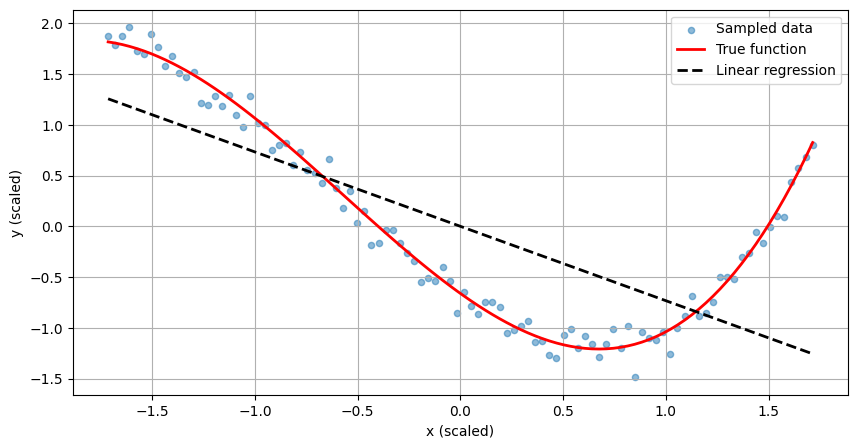

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# Data from a known non-linear function with added noise
np.random.seed(42)

n = 100
x_raw = np.linspace(-2, 2, n)

def g_func(x):
    return x**3 + 2 * x**2 - 5 * x + 2

y_raw = g_func(x_raw) + np.random.normal(0, 0.5, size=n)

# Scale the data to zero mean and unit variance (important for gradient descent)
x_scaled = (x_raw - np.mean(x_raw)) / np.std(x_raw)
y_scaled = (y_raw - np.mean(y_raw)) / np.std(y_raw)

# The network expects 2D arrays: n x 1 for the input and for the target
X = x_scaled.reshape(-1, 1)
y = y_scaled.reshape(-1, 1)
print("X shape:", X.shape, " y shape:", y.shape)

# Best straight line (the single neuron of the previous chapter)
slope, intercept = np.polyfit(x_scaled, y_scaled, deg=1)
line_mse = np.mean((y_scaled - (intercept + slope * x_scaled)) ** 2)
print("MSE of the straight line:", round(line_mse, 4))

plt.figure(figsize=(10, 5))
plt.scatter(x_scaled, y_scaled, alpha=0.5, s=20, label='Sampled data')
plt.plot(x_scaled, (g_func(x_raw) - np.mean(y_raw)) / np.std(y_raw), 'r-', linewidth=2, label='True function')
plt.plot(x_scaled, intercept + slope * x_scaled, 'k--', linewidth=2, label='Linear regression')
plt.xlabel('x (scaled)')
plt.ylabel('y (scaled)')
plt.legend()
plt.grid(True)
plt.show()

## Common Activation Functions

So far we have seen the linear regression model as a simple neural network (one input, no hidden layer) with the identity activation of the output node. Neural networks excel at learning non-linear associations between the input features and the target variable. In order to achieve this, we need to transform the output of the neurons in the hidden layers using non-linear activation functions.

The hidden layers of the neural network enable it to capture non-linear relationships between the input features and the target variable. This is achieved by applying non-linear activation functions to the outputs of the neurons in the hidden layers. Common activation functions include the ReLU (Rectified Linear Unit), sigmoid, and tanh functions.

:::{.ex-class}
$$
\text{ReLU}(z) = \max(0, z)
$$
:::

:::{.ex-class}
$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$
:::

:::{.ex-class}
$$
\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}
$$
:::

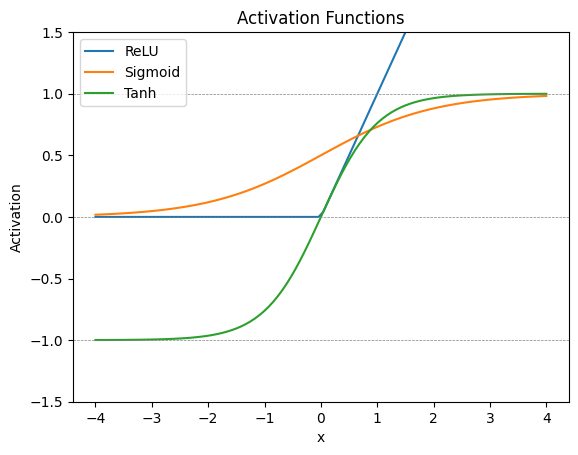

In [2]:
# no-ex-class
import numpy as np
import matplotlib.pyplot as plt

# Plot ReLU, Sigmoid, and Tanh functions

x = np.linspace(-4, 4, 100)

relu = np.maximum(0, x)
sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)

plt.plot(x, relu, label='ReLU')
plt.plot(x, sigmoid, label='Sigmoid')
plt.plot(x, tanh, label='Tanh')
plt.axhline(-1, color='gray', linestyle='--', linewidth=0.5)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axhline(1, color='gray', linestyle='--', linewidth=0.5)
plt.ylim(-1.5, 1.5)
plt.xlabel('x')
plt.ylabel('Activation')
plt.title('Activation Functions')
plt.legend()
plt.show()

## The Model

![Simple Regression with a Hidden Layer](./figures/ann/Linear-Regression-Single-Input-Hidden-Single-Output.png)

For a network with one input, two neurons in the hidden layer, one output and the ReLU activation function we use the following notation for observation $i$ (the input $x_i$ is a scalar):

- $h_{ij}$ is the net value (pre-activation) of hidden neuron $j$,
- $z_{ij} = \text{ReLU}(h_{ij})$ is its activation,
- $w_{hj}$ and $b_{hj}$ are the weight and bias of hidden neuron $j$, $w_{oj}$ is the weight connecting hidden neuron $j$ to the output and $b_o$ is the output bias.

[https://www.desmos.com/calculator/jwruoptwuv](https://www.desmos.com/calculator/jwruoptwuv)

{{< video ./videos/ReluHiddenLayer.mp4 >}}

The hidden layer neurons first compute their net values:

$$
\begin{align*}
h_{i1} & = w_{h1} \cdot x_{i} + b_{h1} \\
h_{i2} & = w_{h2} \cdot x_{i} + b_{h2}
\end{align*}
$$

and the output is the weighted sum of their activations plus the output bias:

$$
\hat{y}_i = w_{o1} \cdot \text{ReLU}(h_{i1}) + w_{o2} \cdot \text{ReLU}(h_{i2}) + b_o
$$

Again, the MSE is the average squared difference between the actual and predicted values:

$$
\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

So the final equation for the output is:

$$
\hat{y}_i = w_{o1} \cdot \underbrace{\text{ReLU}(\overbrace{w_{h1} \cdot x_i + b_{h1}}^{h_{i1}})}_{z_{i1}} + w_{o2} \cdot \underbrace{\text{ReLU}(\overbrace{w_{h2} \cdot x_i + b_{h2}}^{h_{i2}})}_{z_{i2}} + b_o
$$

[https://www.desmos.com/calculator/gmsdth4fmf](https://www.desmos.com/calculator/gmsdth4fmf)

[https://www.desmos.com/calculator/xnywykcn3l](https://www.desmos.com/calculator/xnywykcn3l)

## The Model in Matrix Notation

A convenient way to express the neural network model is using matrix notation as it easily generalizes to multiple input features and multiple output targets and also maps nicely to `numpy` code. We use the row-vector convention of the code below: observations are rows and each layer multiplies from the right.

Let $x$ be a scalar input for a single observation (sample), $W_h \in \mathbb{R}^{1 \times 2}$ the matrix of weights connecting the input to the hidden layer with two neurons, $b_h \in \mathbb{R}^{1 \times 2}$ the bias (row) vector of the hidden layer, $W_o \in \mathbb{R}^{2 \times 1}$ the weight matrix connecting the hidden layer to the output layer, and $b_o \in \mathbb{R}$ the bias of the output layer.

$$
W_h = \begin{bmatrix}
w_{h1} & w_{h2}
\end{bmatrix}
\quad
b_h = \begin{bmatrix}
b_{h1} & b_{h2}
\end{bmatrix}
\quad
W_o = \begin{bmatrix}
w_{o1} \\
w_{o2}
\end{bmatrix}
$$

The net values (pre-activations) of the hidden layer are computed as the input multiplied by the weights plus the biases:

:::{.ex-class}
$$
h = x W_h + b_h = x \begin{bmatrix}
w_{h1} & w_{h2}
\end{bmatrix} + \begin{bmatrix}
b_{h1} & b_{h2}
\end{bmatrix} = \begin{bmatrix}
w_{h1} x + b_{h1} & w_{h2} x + b_{h2}
\end{bmatrix}
$$
:::

The activation of the hidden layer neurons is computed by applying the ReLU activation function element-wise to the net values:

:::{.ex-class}
$$
z = \text{ReLU}(h) = \begin{bmatrix}
\text{ReLU}(w_{h1} x + b_{h1}) & \text{ReLU}(w_{h2} x + b_{h2})
\end{bmatrix}
$$
:::

Finally, the output of the network is computed as the weighted sum of the activations from the hidden layer plus a bias term:

$$
\hat{y} = z W_o + b_o = \begin{bmatrix}
\text{ReLU}(w_{h1} x + b_{h1}) & \text{ReLU}(w_{h2} x + b_{h2})
\end{bmatrix} \begin{bmatrix}
w_{o1} \\
w_{o2}
\end{bmatrix} + b_o
$$

With $n$ observations stacked as the rows of the $n \times 1$ matrix $x$, the same formulas give the matrices $H = x W_h + b_h$ ($n \times 2$, the row vector $b_h$ is added to every row), $Z = \text{ReLU}(H)$ and $\hat{Y} = Z W_o + b_o$.

As an example, let's compute the output of the network for two samples $x = (4, 2)^\top$ and the following weights and biases:

$$
W_h = \begin{bmatrix}
0.25 & 0.5
\end{bmatrix}
\quad
b_h = \begin{bmatrix}
0.1 & -1.1
\end{bmatrix}
\quad
W_o = \begin{bmatrix}
0.4 \\
-0.6
\end{bmatrix}
\quad
b_o = -0.2
$$

So the transformation from the input layer to the (net values of the) hidden layer is:

$$
H = x W_h + b_h = \begin{bmatrix}
4 \\
2
\end{bmatrix} \begin{bmatrix}
0.25 & 0.5
\end{bmatrix} + \begin{bmatrix}
0.1 & -1.1 \\
0.1 & -1.1
\end{bmatrix} = 
\begin{bmatrix}
4 \cdot 0.25 + 0.1 & 4 \cdot 0.5 - 1.1 \\
2 \cdot 0.25 + 0.1 & 2 \cdot 0.5 - 1.1
\end{bmatrix} =
\begin{bmatrix}
1.1 & 0.9 \\
0.6 & -0.1
\end{bmatrix}
$$

Now we have the hidden layer net values (pre-activations) $H$ and we need to pass them through the activation function (ReLU in this case). The ReLU function is applied element-wise to $H$ and gives the hidden layer activations $Z$:

$$
Z = \text{ReLU}(H) = 
\begin{bmatrix}
\text{ReLU}(1.1) & \text{ReLU}(0.9) \\
\text{ReLU}(0.6) & \text{ReLU}(-0.1)
\end{bmatrix} =
\begin{bmatrix}
1.1 & 0.9 \\
0.6 & \mathbf{0}
\end{bmatrix}
$$

The last step in our network is to map the hidden layer after activation ($Z$) to the output layer by another linear transformation:

:::{.ex-class}
$$
\hat{Y} = Z W_o + b_o
$$
:::

Where the output weight matrix has dimension $k \times q$, $k$ is the number of hidden neurons ($k = 2$ here) and $q$ is the number of output targets (for now $q = 1$):

$$
W_o = \begin{bmatrix}
w_{o1} \\
w_{o2} \\
\end{bmatrix} = \begin{bmatrix}
0.4 \\
-0.6 \\
\end{bmatrix}
$$

The output bias vector has dimension $1 \times q$:
$$
b_o = \begin{bmatrix}
b_{o}
\end{bmatrix} = \begin{bmatrix}-0.2\end{bmatrix}
$$

Now we are all set to actually compute the output predictions for our two samples (observations):

$$
\hat{Y} = 
Z W_o + b_o =
\begin{bmatrix}
1.1 & 0.9 \\
0.6 & 0
\end{bmatrix} \begin{bmatrix}
0.4 \\
-0.6
\end{bmatrix} + \begin{bmatrix}
-0.2 \\
-0.2
\end{bmatrix}
= \begin{bmatrix}
1.1 \cdot 0.4 + 0.9 \cdot (-0.6) - 0.2 \\
0.6 \cdot 0.4 + 0 \cdot (-0.6) - 0.2
\end{bmatrix} =
\begin{bmatrix}
-0.3 \\
0.04
\end{bmatrix}
$$

If we have actual target values (for example the ones below) for our two samples, we can compute the MSE loss:

$$
y = \begin{bmatrix}
1.0 \\
0.0
\end{bmatrix}
$$

$$
\text{MSE} = \frac{1}{2} \left( (1.0 - (-0.3))^2 + (0.0 - 0.04)^2 \right) = \frac{1}{2} (1.69 + 0.0016) = 0.8458
$$

The computations of this example are reproduced with NumPy in the [implementation section](#implementation) below.

## Weights Update Equations

Now that we have the predictions we also need to setup the update equations for the weights (the hidden layer weights and biases and the output layer weights and biases).

For this we need the gradients of the loss function with respect to all these parameters. Although this is actually quite easy, one can easily get lost in the derivation, especially when writing the vectorized versions.

### Output Layer Weights and Bias

Let's start with the gradients for the output layer weights and bias. The loss function is exactly the same as before (the factor $-2$ in the second line comes from the chain rule, as before):

$$
L = \text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

$$
\begin{align*}
\frac{\partial L}{\partial w_{o1}} & = \frac{1}{n} \sum_{i=1}^{n} \frac{\partial }{\partial w_{o1}} (y_i - \hat{y}_i)^2 \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) \frac{\partial }{\partial w_{o1}} \hat{y}_i \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) \frac{\partial }{\partial w_{o1}} \left( w_{o1} z_{i1} + w_{o2} z_{i2} + b_o \right) \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) z_{i1}
\end{align*}
$$

In the same way we can derive the gradient with respect to the second output weight:

$$
\begin{align*}
\frac{\partial L}{\partial w_{o2}} & = - \frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) z_{i2}
\end{align*}
$$

When we look at the two partial derivatives we can see that they are only a scaled (by $-\frac{2}{n}$) version of the dot product between the error vector $(y - \hat{y})$ and the respective hidden layer activation vector ($z_{1}$ or $z_{2}$). These vectors hold the data for all the samples.

Let's pack both partial derivatives into a single vectorized equation for the output layer weights:

:::{.ex-class}
$$
\underbrace{\frac{\partial L}{\partial W_o}}_{2 \times 1} = -\frac{2}{n} 
\begin{bmatrix}
\sum_{i=1}^{n} (y_i - \hat{y}_i) z_{i1} \\
\sum_{i=1}^{n} (y_i - \hat{y}_i) z_{i2}
\end{bmatrix} =
-\frac{2}{n} \underbrace{Z^\top}_{2 \times n} \underbrace{(y - \hat{y})}_{n \times 1}
$$
:::

Since $\frac{\partial \hat{y}_i}{\partial b_o} = 1$, the gradient for the output bias is simply

:::{.ex-class}
$$
\frac{\partial L}{\partial b_o} = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)
$$
:::

:::{.callout-note}
## Shapes

Always pay close attention to the shapes of the matrices and vectors involved in the computations.

:::

### Hidden Layer Weights and Biases

As the model predictions depend on the hidden layer weights and biases through the hidden layer activations, we also need to update these during the training, again applying the chain rule for differentiation.

Before we start, let's define the derivative of the ReLU activation function:

:::{.ex-class}
$$
\text{ReLU}'(z) = \begin{cases}
1 & \text{if } z > 0 \\
0 & \text{otherwise}
\end{cases}
$$
:::

You will note that $\text{ReLU}(z) = \max(0, z)$ does not have a derivative at $z = 0$. In practice we _assume_ that the derivative at this point is 0.

With this in mind we can go forward and differentiate the MSE loss with respect to the hidden layer weights and biases. Let's start with the first hidden layer weight $w_{h1}$:

$$
\begin{align*}
\frac{\partial L}{\partial w_{h1}} & = \frac{1}{n} \sum_{i=1}^{n} \frac{\partial }{\partial w_{h1}} (y_i - \hat{y}_i)^2 \quad \text{just as before}\\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) \frac{\partial }{\partial w_{h1}} \hat{y}_i \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) \frac{\partial }{\partial w_{h1}} \left( w_{o1} z_{i1} + w_{o2} z_{i2} + b_o \right) \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) w_{o1} \frac{\partial }{\partial w_{h1}} z_{i1} \quad \text{because the first weight enters the prediction only through } z_{i1} \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) w_{o1} \text{ReLU}'(h_{i1}) \frac{\partial }{\partial w_{h1}} h_{i1} \quad \text{because } z_{i1} = \text{ReLU}(h_{i1}) \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) w_{o1} \text{ReLU}'(h_{i1}) \frac{\partial }{\partial w_{h1}} \left( w_{h1} x_{i} + b_{h1} \right) \quad \text{replace with the definition of } h_{i1} \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) w_{o1} \text{ReLU}'(h_{i1}) x_{i} \\
                                  & = w_{o1} \left(-\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) \text{ReLU}'(h_{i1}) x_{i}\right)
\end{align*}
$$

Running the same calculation for the second hidden layer weight $w_{h2}$ we get:

$$
\begin{align*}
\frac{\partial L}{\partial w_{h2}} & = w_{o2} \left(-\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) \text{ReLU}'(h_{i2}) x_{i}\right)
\end{align*}
$$

In a similar fashion we can also derive the gradients for the hidden layer biases (not shown here). After some algebra we can summarize the gradients for the hidden layer weights and biases in vectorized form. Let

:::{.ex-class}
$$
\underbrace{\Delta}_{n \times k} = \left( (y - \hat{y}) W_o^\top \right) \odot \text{ReLU}'(H)
$$
:::

be the error propagated back to the net values of the hidden neurons ($\odot$ is the element-wise product). Then

:::{.ex-class}
$$
\underbrace{\frac{\partial L}{\partial W_h}}_{1 \times k} = -\frac{2}{n} \underbrace{x^\top}_{1 \times n} \Delta
\qquad
\underbrace{\frac{\partial L}{\partial b_h}}_{1 \times k} = -\frac{2}{n} \underbrace{\mathbf{1}^\top}_{1 \times n} \Delta
$$
:::

Here $k$ is the number of hidden neurons, $x$ is the $n \times 1$ input matrix, $\mathbf{1}$ is a vector of $n$ ones (so $\mathbf{1}^\top$ sums over the observations) and the shapes match the code in the next section (`dW_h`, `db_h`).

## Tanh Activation

Replacing the ReLU activation function with $\tanh$ only changes the last equation:

$$
\begin{align*}
\hat{y}_i & = w_{o1} \tanh(h_{i1}) + w_{o2} \tanh(h_{i2}) + b_{o} \\
\end{align*}
$$

Let's derive the gradients with respect to the weights. The output layer is quite simple:

$$
\begin{align*}
\frac{\partial L}{\partial w_{o1}} & = \frac{1}{n} \sum_{i=1}^{n} \frac{\partial }{\partial w_{o1}} (y_i - \hat{y}_i)^2 \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) \frac{\partial }{\partial w_{o1}} \hat{y}_i \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) \tanh(h_{i1})
\end{align*}
$$

So this partial derivative is a scaled dot product of the errors and the activations of the first hidden neuron. Similarly for the second output weight:

$$
\begin{align*}
\frac{\partial L}{\partial w_{o2}} & = - \frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) \tanh(h_{i2})
\end{align*}
$$

We can pack these two equations into a whole gradient vector for the output weights:

$$
\frac{\partial L}{\partial W_o} = - \frac{2}{n} 
\begin{bmatrix}
\sum_{i=1}^{n} (y_i - \hat{y}_i) \tanh(h_{i1}) \\
\sum_{i=1}^{n} (y_i - \hat{y}_i) \tanh(h_{i2})
\end{bmatrix}
$$

or in vectorized form:

$$
\underbrace{\frac{\partial L}{\partial W_o}}_{2 \times 1} = - \frac{2}{n} 
\underbrace{Z^\top}_{2 \times n} \underbrace{(y - \hat{y})}_{n \times 1}
$$

where $Z = \tanh(H)$ is the $n \times 2$ matrix of hidden layer activations.

The gradients with respect to the hidden layer weights are a bit more involved because we need to apply the chain rule to account for the non-linear activation function. Let's derive the gradient with respect to the first hidden layer weight $w_{h1}$. Before we do this, note that the derivative of the $\tanh$ function is:

$$
\frac{d}{d h} \tanh(h) = 1 - \tanh^2(h)
$$

$$
\begin{align*}
\frac{\partial L}{\partial w_{h1}} & = \frac{\partial }{\partial w_{h1}} \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 \\
                                  & =   -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) \frac{\partial }{\partial w_{h1}} \hat{y}_i \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) \frac{\partial }{\partial w_{h1}} \left( w_{o1} \tanh(h_{i1}) + w_{o2} \tanh(h_{i2}) + b_{o} \right) \\
                                  & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) w_{o1} \frac{\partial }{\partial w_{h1}} \tanh(h_{i1}) \\
                                    & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) w_{o1} \left( 1 - \tanh^2(h_{i1}) \right) \frac{\partial }{\partial w_{h1}} h_{i1} \\
                                    & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) w_{o1} \left( 1 - \tanh^2(h_{i1}) \right) x_{i} \\
\end{align*}
$$

For the second hidden layer weight $w_2$ the derivation is similar:

$$
\begin{align*}
\frac{\partial L}{\partial w_{h2}} & = -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i) w_{o2} \left( 1 - \tanh^2(h_{i2}) \right) x_{i} \\
\end{align*}
$$

## Implementation {#implementation}

### The worked example in NumPy

The next two cells reproduce the example with the two samples $x = (4, 2)^\top$ from above.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([[4], [2]])
print("Input matrix shape:", x.shape)
print(x)

W_h = np.array([[0.25, 0.5]]).reshape(-1, 2)
print("Hidden layer weights shape:", W_h.shape)
print(W_h)

b_h = np.array([0.1, -1.1]).reshape(-1, 2)
print("Hidden layer biases shape:", b_h.shape)
print(b_h)

# Compute hidden layer net values (pre-activations)

H = x @ W_h + b_h
print("Hidden layer shape:", H.shape)
print(H)

def relu(x):
    return np.maximum(0, x)

Z = relu(H)
print("Activated hidden layer shape:", Z.shape)
print(Z)

W_o = np.array([0.4, -0.6]).reshape(-1, 1)

print("Output layer weights shape:", W_o.shape)
print(W_o)

b_o = np.array([-0.2]).reshape(-1, 1)
print("Output layer biases shape:", b_o.shape)
print(b_o)

y_pred = Z @ W_o + b_o
print("Output shape:", y_pred.shape)
print(y_pred)

y_example = np.array([[1.0], [0.0]])
print("Target shape:", y_example.shape)
print(y_example)

np.mean((y_example - y_pred)**2)

Input matrix shape: (2, 1)
[[4]
 [2]]
Hidden layer weights shape: (1, 2)
[[0.25 0.5 ]]
Hidden layer biases shape: (1, 2)
[[ 0.1 -1.1]]
Hidden layer shape: (2, 2)
[[ 1.1  0.9]
 [ 0.6 -0.1]]
Activated hidden layer shape: (2, 2)
[[1.1 0.9]
 [0.6 0. ]]
Output layer weights shape: (2, 1)
[[ 0.4]
 [-0.6]]
Output layer biases shape: (1, 1)
[[-0.2]]
Output shape: (2, 1)
[[-0.3 ]
 [ 0.04]]
Target shape: (2, 1)
[[1.]
 [0.]]


np.float64(0.8457999999999998)

In [4]:
# no-ex-class
n_example = len(y_example)
dL_dW_o = -(2 / n_example) * Z.T @ (y_example - y_pred)
print("Gradient shape (output layer):", dL_dW_o.shape)
print(dL_dW_o)

dL_db_o = -(2 / n_example) * np.sum(y_example - y_pred)
print("Gradient (output bias):", dL_db_o)

Gradient shape (output layer): (2, 1)
[[-1.406]
 [-1.17 ]]
Gradient (output bias): -1.2599999999999998


### Training with NumPy

The network is trained on the cubic data with the gradients derived above, first with NumPy and then with PyTorch.

W_h shape: (1, 3)
b_h shape: (1, 3)
W_o shape: (3, 1)
b_o shape: (1, 1)
X shape: (100, 1)
y shape: (100, 1)


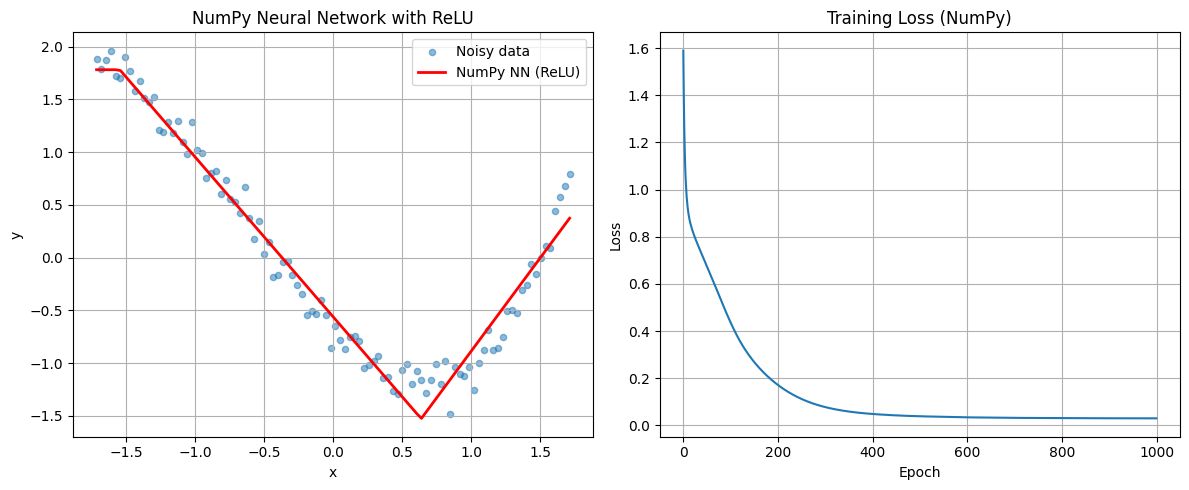

In [5]:
# Neural network regression using NumPy with ReLU activation

# First we set the random seed for reproducibility
# as it is used to initialize the weights

np.random.seed(42)

# Number of hidden units (the example above used 2, here we use 3)
k = 3

# Initialize the weights and biases (He initialization for ReLU: variance 2 / fan_in)
W_h = np.random.randn(1, k) * np.sqrt(2.0 / 1)
b_h = np.zeros((1, k))
W_o = np.random.randn(k, 1) * np.sqrt(2.0 / k)
b_o = np.zeros((1, 1))

# Sanity check: print the shapes of the weights and biases
print("W_h shape:", W_h.shape)
print("b_h shape:", b_h.shape)
print("W_o shape:", W_o.shape)
print("b_o shape:", b_o.shape)

print("X shape:", X.shape)
print("y shape:", y.shape)

# Some helper function to make the code
# below easier to read

def relu(x):
    return np.maximum(0, x)

def relu_prime(x):
    return (x > 0).astype(float)

# Training parameters: plain full-batch gradient descent
epochs = 1000
learning_rate = 0.03
losses_np = []

# Training loop
for epoch in range(epochs):
    # Forward pass (calculate predictions)

    H = X @ W_h + b_h
    Z = relu(H)
    y_pred = Z @ W_o + b_o
    
    # Compute loss (MSE)
    loss = np.mean((y - y_pred) ** 2)
    losses_np.append(loss)
    
    # Backward pass
    dLoss_dy = -2 * (y - y_pred) / n
    
    # Output layer gradients
    dW_o = Z.T @ dLoss_dy
    db_o = np.sum(dLoss_dy)
    
    # Hidden layer gradients
    dZ = dLoss_dy @ W_o.T
    dH = dZ * relu_prime(H) # Note the element-wise (not matrix) multiplication here
    dW_h = X.T @ dH
    db_h = np.sum(dH, axis=0, keepdims=True)
    
    # Update weights and biases
    W_o -= learning_rate * dW_o
    b_o -= learning_rate * db_o
    W_h -= learning_rate * dW_h
    b_h -= learning_rate * db_h

# Final predictions (after the training loop)
H = X @ W_h + b_h
Z = relu(H)

y_pred_final_np = Z @ W_o + b_o

# Plot results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X, y, alpha=0.5, s=20, label='Noisy data')
plt.plot(X, y_pred_final_np, 'r-', label='NumPy NN (ReLU)', linewidth=2)
plt.xlabel('x')
plt.ylabel('y')
plt.title('NumPy Neural Network with ReLU')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(losses_np)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss (NumPy)')
plt.grid(True)

plt.tight_layout()
plt.show()

The NumPy network above is trained with plain full-batch gradient descent ($\eta = 0.03$). The PyTorch version below uses the Adam optimizer ($\eta = 0.01$), so the two fits will not be identical even with the same architecture. PyTorch computes the gradients derived above automatically (`loss.backward()`).

x_train shape: torch.Size([100, 1])
y_train shape: torch.Size([100, 1])


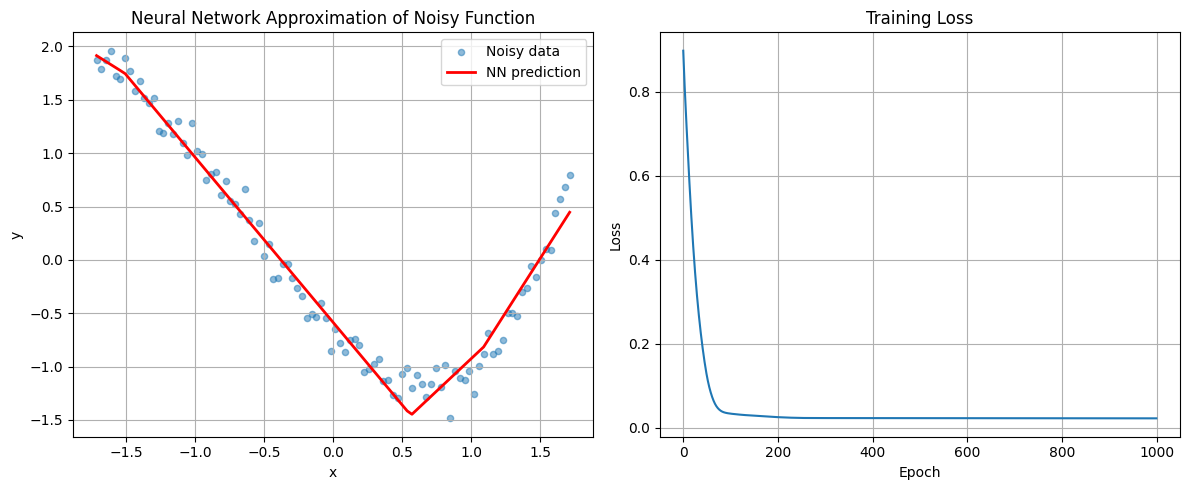

In [6]:
# Neural network regression using PyTorch

np.random.seed(42)
torch.manual_seed(42)

## Prepare the data
## torch has its own data structures called tensors
## and we need to convert the numpy arrays to tensors
## 
## Furthermore, the input to the network should be
## a 2D array (matrix) even if there is only one feature
## so the input shape should be (n, n_features)
## The output should also be a 2D array even if there is only one target
## 

x_train = torch.from_numpy(X).float()
y_train = torch.from_numpy(y).float()

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)

################################
## This is the important part
################################

# Define the neural network
class TorchNN(nn.Module):
    def __init__(self, k=3):
        super().__init__()
        self.k = k

        self.input_to_hidden = nn.Linear(1, k)
        self.hidden_activation = nn.ReLU()
        self.output_layer = nn.Linear(k, 1)
    
    # Compute the forward pass (prediction)    
    def forward(self, x):
        # Map the input to hidden layer
        x = self.input_to_hidden(x)
        # Then apply activation to the result
        x = self.hidden_activation(x)

        # Then map the activated hidden layer to output
        x = self.output_layer(x)

        return x
    
##########################################
## The rest of the code runs the gradient
## descent algorithm to find the optimal 
## weights that minimize the MSE loss
##########################################

# Initialize model, loss, and optimizer
model = TorchNN(k=3)

criterion = nn.MSELoss()

# Note: Adam instead of the plain gradient descent used in the NumPy version
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Training loop

# How many times to iterate over the whole dataset 
# (one such iteration is called an epoch)

epochs = 1000
losses = []

for epoch in range(epochs):
    # Forward pass
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    losses.append(loss.item())
    
    # Backward pass
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# Get predictions
with torch.no_grad():
    y_pred_final = model(x_train)

# Plot results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(x_train, y_train, alpha=0.5, s=20, label='Noisy data')
plt.plot(x_train, y_pred_final.numpy(), 'r-', label='NN prediction', linewidth=2)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Neural Network Approximation of Noisy Function')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.grid(True)

plt.tight_layout()
plt.show()

In [7]:
# no-ex-class
# Run a prediction with the trained model
# The model was trained on the scaled data, so the input (1.5) is on the
# scaled x axis and the prediction is on the scaled y axis

x_new_scaled = 1.5
with torch.no_grad():
    y_new_scaled = model(torch.tensor([[x_new_scaled]])).item()

# Transform back to the original units
x_new = x_new_scaled * np.std(x_raw) + np.mean(x_raw)
y_new = y_new_scaled * np.std(y_raw) + np.mean(y_raw)

print("Scaled: x =", x_new_scaled, "-> y =", round(y_new_scaled, 4))
print("Original units: x =", round(x_new, 4), "-> y =", round(y_new, 4))
print("True function at this x:", round(g_func(x_new), 4))

Scaled: x = 1.5 -> y = 0.0111
Original units: x = 1.7495 -> y = 4.7133
True function at this x: 4.7283


In [8]:
# no-ex-class
# Inspect the learned weights

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, param.data)

input_to_hidden.weight tensor([[ 0.9106],
        [ 1.9028],
        [-0.7392]])
input_to_hidden.bias tensor([ 1.3736, -1.0723,  0.8066])
output_layer.weight tensor([[-0.8083,  1.4507,  1.0964]])
output_layer.bias tensor([-0.3598])


The `weight` of a PyTorch `nn.Linear(in, out)` layer has shape `(out, in)`, so `input_to_hidden.weight` is the **transpose** of $W_h$ ($k \times 1$ instead of $1 \times k$) and `output_layer.weight` is the transpose of $W_o$ ($1 \times k$ instead of $k \times 1$). The biases correspond to $b_h$ and $b_o$.

## What's next

In the [next chapter](03-05-ANN-Multiple-Regression.ipynb) we add more input features. The matrix formulas of this chapter carry over unchanged, with the $n \times 1$ input $x$ replaced by the $n \times p$ matrix $X$. Multiple linear regression without a hidden layer then appears as a special case.